**Thử nghiệm chọn K**

In [ ]:
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

# =============================================================================
# 1. THIẾT LẬP ĐƯỜNG DẪN VÀ NẠP DỮ LIỆU FEATURE SCALED
# =============================================================================
sys.path.append("..")

BASE_DIR = Path("..")
paths = {
    "processed": BASE_DIR / "data" / "processed",
    "figures": BASE_DIR / "reports" / "figures",
    "tables": BASE_DIR / "reports" / "tables",
    "models": BASE_DIR / "models",
}

for p in paths.values():
  p.mkdir(parents=True, exist_ok=True)


def load_scaled_features(paths: dict):
  """Chỉ đọc file rfm_features_scaled.csv đã được xử lý từ bước trước."""
  rfm_features_path = paths["processed"] / "rfm_features_scaled.csv"

  if not rfm_features_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy file đặc trưng: {rfm_features_path.resolve()}"
    )

  rfm_features = pd.read_csv(rfm_features_path)
  print(
      f" Nạp dữ liệu thành công từ: {rfm_features_path.name} ({len(rfm_features):,} dòng)"
  )
  return rfm_features

In [12]:
from pathlib import Path
import pandas as pd
from src.rfm import RFMProcessor
cleaned_file_path = paths["processed"] / "olist_cleaned_dataset.csv"
df_clean = pd.read_csv(cleaned_file_path)
df_clean["order_purchase_timestamp"] = pd.to_datetime(
    df_clean["order_purchase_timestamp"]
)

# 3. Tận dụng class RFMProcessor từ src/rfm.py để lấy bảng rfm thô
rfm_processor = RFMProcessor(df_clean)
rfm = rfm_processor.compute_rfm()

 Đã tính RFM thô cho 93,357 khách hàng duy nhất.


 Nạp dữ liệu thành công từ: rfm_features_scaled.csv (93,357 dòng)

QUÉT DẢI K (2 -> 10) BẰNG 4 CHỈ SỐ ĐỊNH LƯỢNG
[*] Dùng sample 10,000 dòng tính Silhouette để chống tràn RAM.
  + K =  2 | WCSS:   184224.4 | Silhouette: 0.7234 | CH:   48569.9 | DB: 0.3992 (1.40s)
  + K =  3 | WCSS:   122459.6 | Silhouette: 0.4114 | CH:   60075.9 | DB: 0.8160 (1.46s)
  + K =  4 | WCSS:    75446.8 | Silhouette: 0.4002 | CH:   84396.8 | DB: 0.7355 (1.29s)
  + K =  5 | WCSS:    61078.9 | Silhouette: 0.3607 | CH:   83676.4 | DB: 0.7991 (1.38s)
  + K =  6 | WCSS:    51263.5 | Silhouette: 0.3604 | CH:   83333.2 | DB: 0.7852 (1.49s)
  + K =  7 | WCSS:    43924.2 | Silhouette: 0.3607 | CH:   83648.0 | DB: 0.7940 (1.43s)
  + K =  8 | WCSS:    38216.6 | Silhouette: 0.3536 | CH:   84395.5 | DB: 0.8242 (3.23s)
  + K =  9 | WCSS:    33974.6 | Silhouette: 0.3427 | CH:   84522.5 | DB: 0.7987 (5.79s)
  + K = 10 | WCSS:    31469.2 | Silhouette: 0.3385 | CH:   81937.9 | DB: 0.8163 (6.39s)


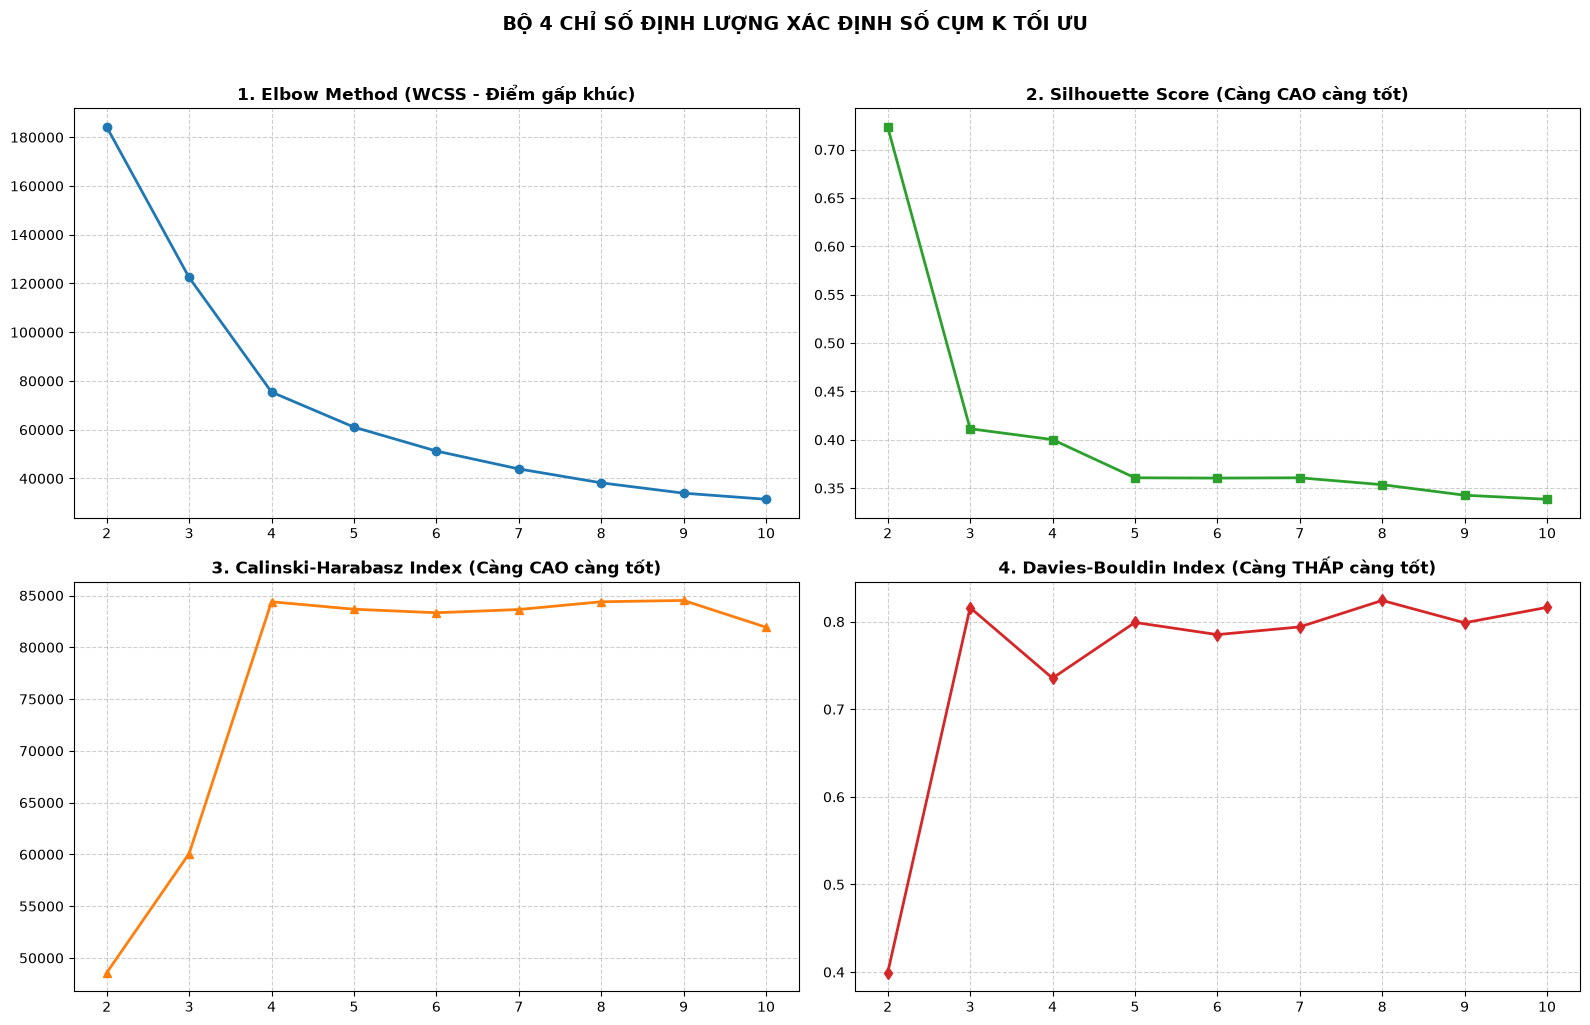


KIỂM CHỨNG CHÉO SỐ CỤM K BẰNG DENDROGRAM (Sample = 5,000)


C:\Users\thao\AppData\Local\Temp\ipykernel_2520\664044735.py:109: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\thao\AppData\Local\Temp\ipykernel_2520\664044735.py:110: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(paths["figures"] / "hierarchical_dendrogram_check.png", dpi=300, bbox_inches='tight')


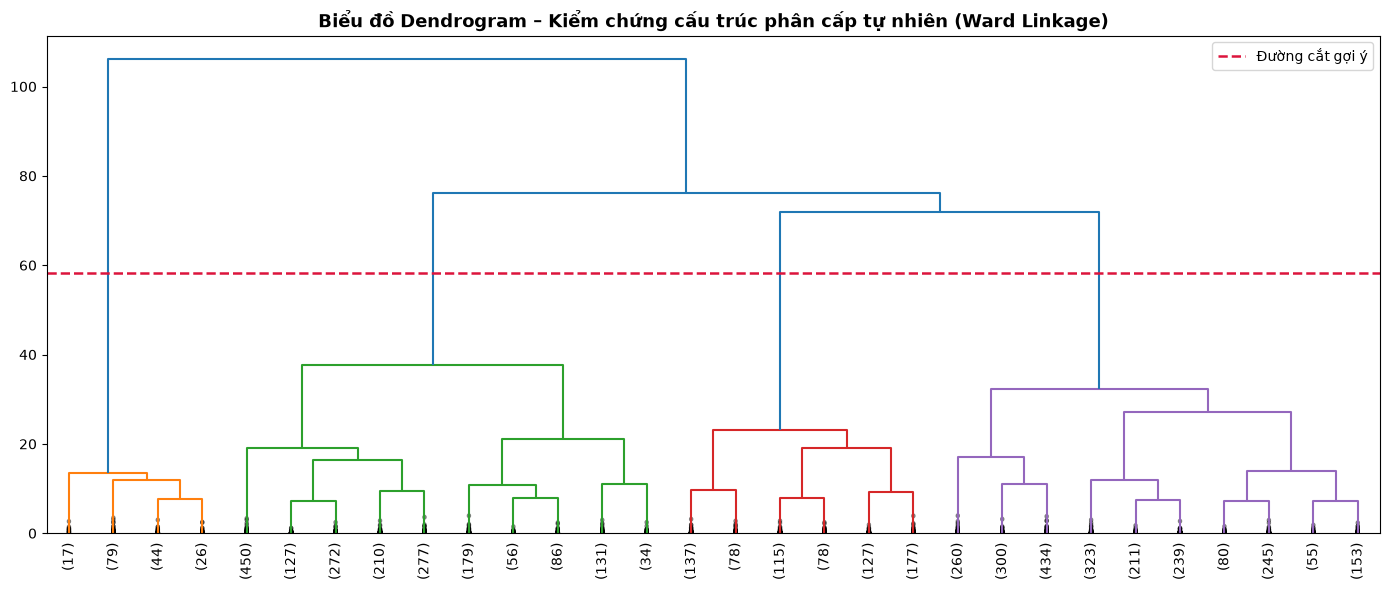


1. VẼ HEATMAP CHÂN DUNG RFM TRỰC QUAN (K = [4, 5])
✅ Đã lưu file Heatmap tại: D:\Machine Learning\PROJECT REPO\reports\figures\k4_vs_k5_visual_comparison.png


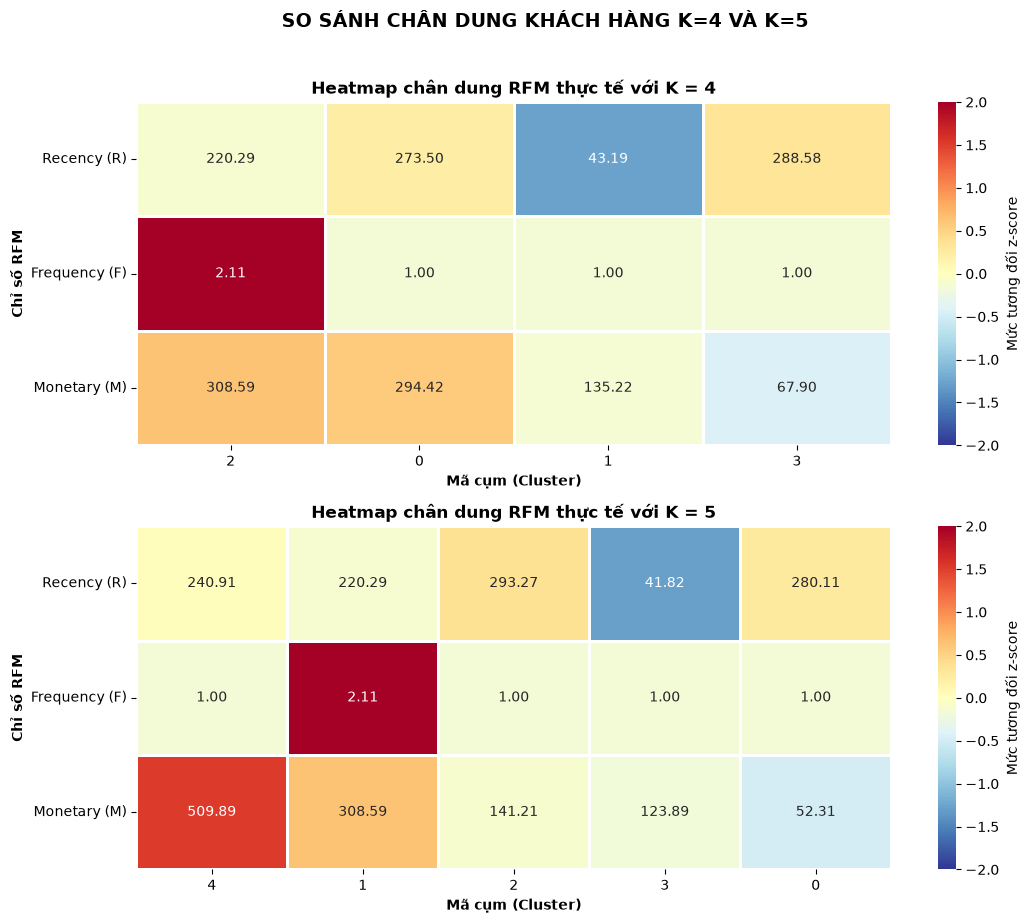


2. VẼ BIỂU ĐỒ CỘT QUY MÔ CỤM (K = [4, 5])
✅ Đã lưu file Quy mô cụm tại: D:\Machine Learning\PROJECT REPO\reports\figures\k4_vs_k5_cluster_sizes.png


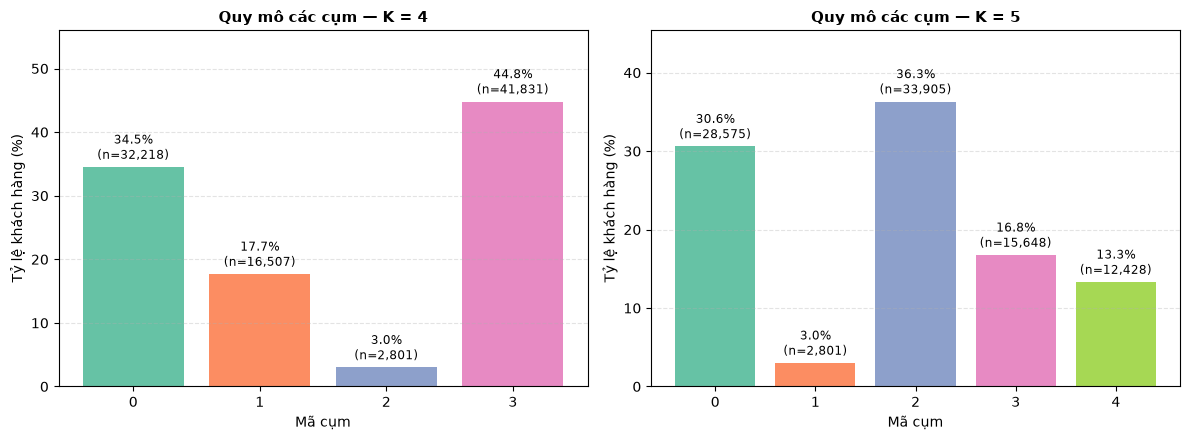


🎯 K được chọn để xây dựng mô hình: K_OPT = 4

BẢNG ĐỐI CHIẾU ĐỊNH LƯỢNG K=4 VÀ K=5:
 K  Inertia_WCSS  Silhouette_Score  Calinski_Harabasz  Davies_Bouldin  Time_sec
 4      75446.78            0.4002           84396.84          0.7355      1.29
 5      61078.92            0.3607           83676.38          0.7991      1.38

NHẬN XÉT TỰ ĐỘNG (cần kết hợp với heatmap và hiểu biết nghiệp vụ):
- Silhouette: K=4 là 0.4002; K=5 là 0.3607 (cao hơn thường tốt hơn).
- Davies–Bouldin: K=4 là 0.7355; K=5 là 0.7991 (thấp hơn thường tốt hơn).
- Calinski–Harabasz: K=4 là 84396.84; K=5 là 83676.38 (cao hơn thường tốt hơn).
- Không dùng riêng một chỉ số để quyết định K. Hãy kiểm tra cả hồ sơ RFM, quy mô cụm và độ ổn định.

ĐỘ ỔN ĐỊNH K-MEANS THEO NHIỀU RANDOM SEED (ARI gần 1 là ổn định hơn):
 K  ARI_mean_vs_first_seed  ARI_min_vs_first_seed  Num_seeds
 4                  0.9959                 0.9950          5
 5                  0.9934                 0.9916          5


In [ ]:
# Đảm bảo đầy đủ các thư mục đầu ra
paths["models"] = Path("models")
for p in paths.values():
    p.mkdir(parents=True, exist_ok=True)

rfm_features = load_scaled_features(paths)
FEATURE_COLS_SCALED = ['Recency_log_scaled', 'Frequency_log_scaled', 'Monetary_log_scaled']
X_scaled = rfm_features[FEATURE_COLS_SCALED].values


# =============================================================================
# HÀM BỔ TRỢ: ĐỒNG BỘ NHÃN CỤM GIỮA CÁC MÔ HÌNH (LABEL ALIGNMENT)
# =============================================================================
def align_clusters_to_reference(ref_centers, target_centers, target_labels, target_probs=None):
    """Sử dụng thuật toán Hungarian để đồng bộ thứ tự cụm của mô hình mục tiêu theo mô hình gốc (K-Means)"""
    cost_matrix = cdist(ref_centers, target_centers, metric='euclidean')
    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    inv_map = {old_label: new_label for new_label, old_label in enumerate(col_ind)}

    aligned_labels = np.vectorize(inv_map.get)(target_labels)
    aligned_centers = target_centers[col_ind]
    aligned_probs = target_probs[:, col_ind] if target_probs is not None else None

    return aligned_centers, aligned_labels, aligned_probs


# =============================================================================
# TÌM SỐ CỤM K TỐI ƯU (HYBRID APPROACH: 4 METRICS + HIERARCHICAL DENDROGRAM)
# =============================================================================

def evaluate_k_range(X: np.ndarray, k_range=range(2, 11), sample_size=10000, random_state=42) -> pd.DataFrame:
    print("\n" + "=" * 75)
    print(f"QUÉT DẢI K ({min(k_range)} -> {max(k_range)}) BẰNG 4 CHỈ SỐ ĐỊNH LƯỢNG")
    print("=" * 75)

    rng = np.random.default_rng(random_state)
    if len(X) > sample_size:
        sample_idx = rng.choice(len(X), size=sample_size, replace=False)
        X_sample = X[sample_idx]
        print(f"[*] Dùng sample {sample_size:,} dòng tính Silhouette để chống tràn RAM.")
    else:
        sample_idx = np.arange(len(X))
        X_sample = X

    results = []
    for k in k_range:
        t0 = time.time()
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10, max_iter=300)
        labels = km.fit_predict(X)

        wcss = km.inertia_
        sil = silhouette_score(X_sample, labels[sample_idx], random_state=random_state)
        ch = calinski_harabasz_score(X, labels)
        db = davies_bouldin_score(X, labels)
        elapsed = time.time() - t0

        results.append({
            "K": k, "Inertia_WCSS": round(wcss, 2), "Silhouette_Score": round(sil, 4),
            "Calinski_Harabasz": round(ch, 2), "Davies_Bouldin": round(db, 4), "Time_sec": round(elapsed, 2)
        })
        print(f"  + K = {k:2d} | WCSS: {wcss:10.1f} | Silhouette: {sil:.4f} | CH: {ch:9.1f} | DB: {db:.4f} ({elapsed:.2f}s)")

    metrics_df = pd.DataFrame(results)
    metrics_df.to_csv(paths["tables"] / "k_selection_metrics.csv", index=False)

    # Trực quan hóa
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    k_vals = metrics_df["K"]

    axes[0, 0].plot(k_vals, metrics_df["Inertia_WCSS"], marker='o', color='#1f77b4', linewidth=2)
    axes[0, 0].set_title("1. Elbow Method (WCSS - Điểm gấp khúc)", fontweight='bold')

    axes[0, 1].plot(k_vals, metrics_df["Silhouette_Score"], marker='s', color='#2ca02c', linewidth=2)
    axes[0, 1].set_title("2. Silhouette Score (Càng CAO càng tốt)", fontweight='bold')

    axes[1, 0].plot(k_vals, metrics_df["Calinski_Harabasz"], marker='^', color='#ff7f0e', linewidth=2)
    axes[1, 0].set_title("3. Calinski-Harabasz Index (Càng CAO càng tốt)", fontweight='bold')

    axes[1, 1].plot(k_vals, metrics_df["Davies_Bouldin"], marker='d', color='#d62728', linewidth=2)
    axes[1, 1].set_title("4. Davies-Bouldin Index (Càng THẤP càng tốt)", fontweight='bold')

    for ax in axes.flat:
        ax.set_xticks(k_vals)
        ax.grid(True, linestyle='--', alpha=0.6)

    plt.suptitle("BỘ 4 CHỈ SỐ ĐỊNH LƯỢNG XÁC ĐỊNH SỐ CỤM K TỐI ƯU", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(paths["figures"] / "k_selection_4_metrics.png", dpi=300, bbox_inches='tight')
    plt.show()

    return metrics_df


def plot_hierarchical_dendrogram(X: np.ndarray, sample_size=5000, random_state=42):
    print("\n" + "=" * 75)
    print(f"KIỂM CHỨNG CHÉO SỐ CỤM K BẰNG DENDROGRAM (Sample = {sample_size:,})")
    print("=" * 75)

    rng = np.random.default_rng(random_state)
    X_sub = X[rng.choice(len(X), size=min(sample_size, len(X)), replace=False)]

    Z = linkage(X_sub, method='ward', metric='euclidean')
    plt.figure(figsize=(14, 6))
    dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10.,
               show_contracted=True, color_threshold=0.65 * max(Z[:, 2]))
    plt.title("Biểu đồ Dendrogram – Kiểm chứng cấu trúc phân cấp tự nhiên (Ward Linkage)", fontsize=13, fontweight='bold')
    plt.axhline(y=0.55 * max(Z[:, 2]), color='crimson', linestyle='--', linewidth=1.8, label='Đường cắt gợi ý')
    plt.legend()
    plt.tight_layout()
    plt.savefig(paths["figures"] / "hierarchical_dendrogram_check.png", dpi=300, bbox_inches='tight')
    plt.show()

k_metrics_df = evaluate_k_range(X_scaled, k_range=range(2, 11), sample_size=10000)
plot_hierarchical_dendrogram(X_scaled, sample_size=5000)


# =============================================================================
# SO SÁNH & TRỰC QUAN HÓA ỨNG CỬ VIÊN K=4 VÀ K=5 
# =============================================================================

def plot_k_comparison_heatmap(
    X: np.ndarray, rfm_orig: pd.DataFrame, paths: dict, candidate_ks=(4, 5)
):
  """Hàm 1: Chỉ vẽ và lưu Heatmap chân dung RFM."""
  print("\n" + "=" * 75)
  print(f"1. VẼ HEATMAP CHÂN DUNG RFM TRỰC QUAN (K = {list(candidate_ks)})")
  print("=" * 75)

  rfm_cols = ["R_Mean", "F_Mean", "M_Mean"]
  source_cols = ["Recency", "Frequency", "Monetary"]
  global_mean = rfm_orig[source_cols].mean()
  global_std = rfm_orig[source_cols].std(ddof=0).replace(0, 1)

  profiles = {}
  fig, axes = plt.subplots(
      len(candidate_ks), 1, figsize=(11, 4.5 * len(candidate_ks))
  )
  if len(candidate_ks) == 1:
    axes = [axes]

  for idx, k in enumerate(candidate_ks):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)

    temp = rfm_orig.copy()
    temp["Cluster"] = labels

    profile = (
        temp.groupby("Cluster")
        .agg(
            Count=("customer_unique_id", "count"),
            R_Mean=("Recency", "mean"),
            F_Mean=("Frequency", "mean"),
            M_Mean=("Monetary", "mean"),
        )
        .reset_index()
        .round(2)
        .sort_values("M_Mean", ascending=False)
    )
    profiles[k] = profile

    profile_values = profile.set_index("Cluster")[rfm_cols]
    global_mean_profile = pd.Series(
        [
            global_mean["Recency"],
            global_mean["Frequency"],
            global_mean["Monetary"],
        ],
        index=rfm_cols,
    )
    global_std_profile = pd.Series(
        [
            global_std["Recency"],
            global_std["Frequency"],
            global_std["Monetary"],
        ],
        index=rfm_cols,
    )
    profile_zscore = (
        profile_values - global_mean_profile
    ) / global_std_profile

    sns.heatmap(
        profile_zscore.T,
        annot=profile_values.T,
        fmt=".2f",
        cmap="RdYlBu_r",
        center=0,
        vmin=-2,
        vmax=2,
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"label": "Mức tương đối z-score"},
        annot_kws={"size": 10},
        ax=axes[idx],
    )
    axes[idx].set_title(
        f"Heatmap chân dung RFM thực tế với K = {k}",
        fontsize=12,
        fontweight="bold",
    )
    axes[idx].set_xlabel("Mã cụm (Cluster)", fontweight="bold")
    axes[idx].set_ylabel("Chỉ số RFM", fontweight="bold")
    axes[idx].set_yticklabels(
        ["Recency (R)", "Frequency (F)", "Monetary (M)"], rotation=0
    )

  fig.suptitle(
      "SO SÁNH CHÂN DUNG KHÁCH HÀNG K=4 VÀ K=5",
      fontsize=14,
      fontweight="bold",
      y=1.02,
  )
  fig.tight_layout()

  save_path = paths["figures"] / "k4_vs_k5_visual_comparison.png"
  fig.savefig(save_path, dpi=300, bbox_inches="tight")
  print(f"✅ Đã lưu file Heatmap tại: {save_path.resolve()}")
  plt.show()

  return profiles


def plot_k_comparison_bars(
    profiles: dict, paths: dict, candidate_ks=(4, 5)
):
  """Hàm 2: Chỉ vẽ và lưu Biểu đồ cột Quy mô các cụm."""
  print("\n" + "=" * 75)
  print(f"2. VẼ BIỂU ĐỒ CỘT QUY MÔ CỤM (K = {list(candidate_ks)})")
  print("=" * 75)

  fig, axes = plt.subplots(1, len(candidate_ks), figsize=(12, 4.5))
  if len(candidate_ks) == 1:
    axes = [axes]

  for ax, k in zip(axes, candidate_ks):
    p = profiles[k].sort_values("Cluster")
    shares = p["Count"] / p["Count"].sum() * 100
    bars = ax.bar(
        p["Cluster"].astype(str),
        shares,
        color=sns.color_palette("Set2", n_colors=len(p)),
    )
    ax.bar_label(
        bars,
        labels=[f"{v:.1f}%\n(n={n:,})" for v, n in zip(shares, p["Count"])],
        padding=3,
        fontsize=8.5,
    )
    ax.set_title(f"Quy mô các cụm — K = {k}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Mã cụm")
    ax.set_ylabel("Tỷ lệ khách hàng (%)")
    ax.set_ylim(0, max(shares) * 1.25)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

  fig.tight_layout()

  save_path = paths["figures"] / "k4_vs_k5_cluster_sizes.png"
  fig.savefig(save_path, dpi=300, bbox_inches="tight")
  print(f"✅ Đã lưu file Quy mô cụm tại: {save_path.resolve()}")
  plt.show()

candidate_profiles = plot_k_comparison_heatmap(
    X_scaled, rfm, paths, candidate_ks=(4, 5)
)
plot_k_comparison_bars(candidate_profiles, paths, candidate_ks=(4, 5))

K_OPT = 4
print(f"\n🎯 K được chọn để xây dựng mô hình: K_OPT = {K_OPT}")
print("\nBẢNG ĐỐI CHIẾU ĐỊNH LƯỢNG K=4 VÀ K=5:")
comparison_k = k_metrics_df[k_metrics_df['K'].isin([4, 5])].copy()
print(comparison_k.to_string(index=False))

if set(comparison_k['K']) == {4, 5}:
    row4 = comparison_k.loc[comparison_k['K'] == 4].iloc[0]
    row5 = comparison_k.loc[comparison_k['K'] == 5].iloc[0]
    print("\nNHẬN XÉT TỰ ĐỘNG (cần kết hợp với heatmap và hiểu biết nghiệp vụ):")
    print(f"- Silhouette: K=4 là {row4['Silhouette_Score']:.4f}; K=5 là {row5['Silhouette_Score']:.4f} (cao hơn thường tốt hơn).")
    print(f"- Davies–Bouldin: K=4 là {row4['Davies_Bouldin']:.4f}; K=5 là {row5['Davies_Bouldin']:.4f} (thấp hơn thường tốt hơn).")
    print(f"- Calinski–Harabasz: K=4 là {row4['Calinski_Harabasz']:.2f}; K=5 là {row5['Calinski_Harabasz']:.2f} (cao hơn thường tốt hơn).")
    print("- Không dùng riêng một chỉ số để quyết định K. Hãy kiểm tra cả hồ sơ RFM, quy mô cụm và độ ổn định.")


def evaluate_kmeans_stability(X: np.ndarray, candidate_ks=(4, 5), seeds=(11, 21, 42, 52, 62)) -> pd.DataFrame:
    """Đánh giá độ ổn định K-Means giữa các seed bằng Adjusted Rand Index (ARI)."""
    rows = []
    for k in candidate_ks:
        labels_by_seed = []
        for seed in seeds:
            labels = KMeans(n_clusters=k, random_state=seed, n_init=10, max_iter=300).fit_predict(X)
            labels_by_seed.append(labels)
        # ARI không phụ thuộc tên/mã cụm; so sánh mỗi lần chạy với lần đầu.
        aris = [adjusted_rand_score(labels_by_seed[0], other) for other in labels_by_seed[1:]]
        rows.append({
            'K': k,
            'ARI_mean_vs_first_seed': float(np.mean(aris)) if aris else np.nan,
            'ARI_min_vs_first_seed': float(np.min(aris)) if aris else np.nan,
            'Num_seeds': len(seeds)
        })
    stability_df = pd.DataFrame(rows)
    stability_df.to_csv(paths['tables'] / 'k4_k5_stability_ari.csv', index=False)
    print("\nĐỘ ỔN ĐỊNH K-MEANS THEO NHIỀU RANDOM SEED (ARI gần 1 là ổn định hơn):")
    print(stability_df.round(4).to_string(index=False))
    return stability_df

stability_df = evaluate_kmeans_stability(X_scaled, candidate_ks=(4, 5))

**K-Means**

✅ Train K-Means (K=4) thành công!
💾 Đã lưu mô hình tại: ../models/kmeans_rfm_model.pkl
📊 Đã lưu DataFrame chứa nhãn cụm tại: ../data/processed/rfm_kmeans_clustered.csv


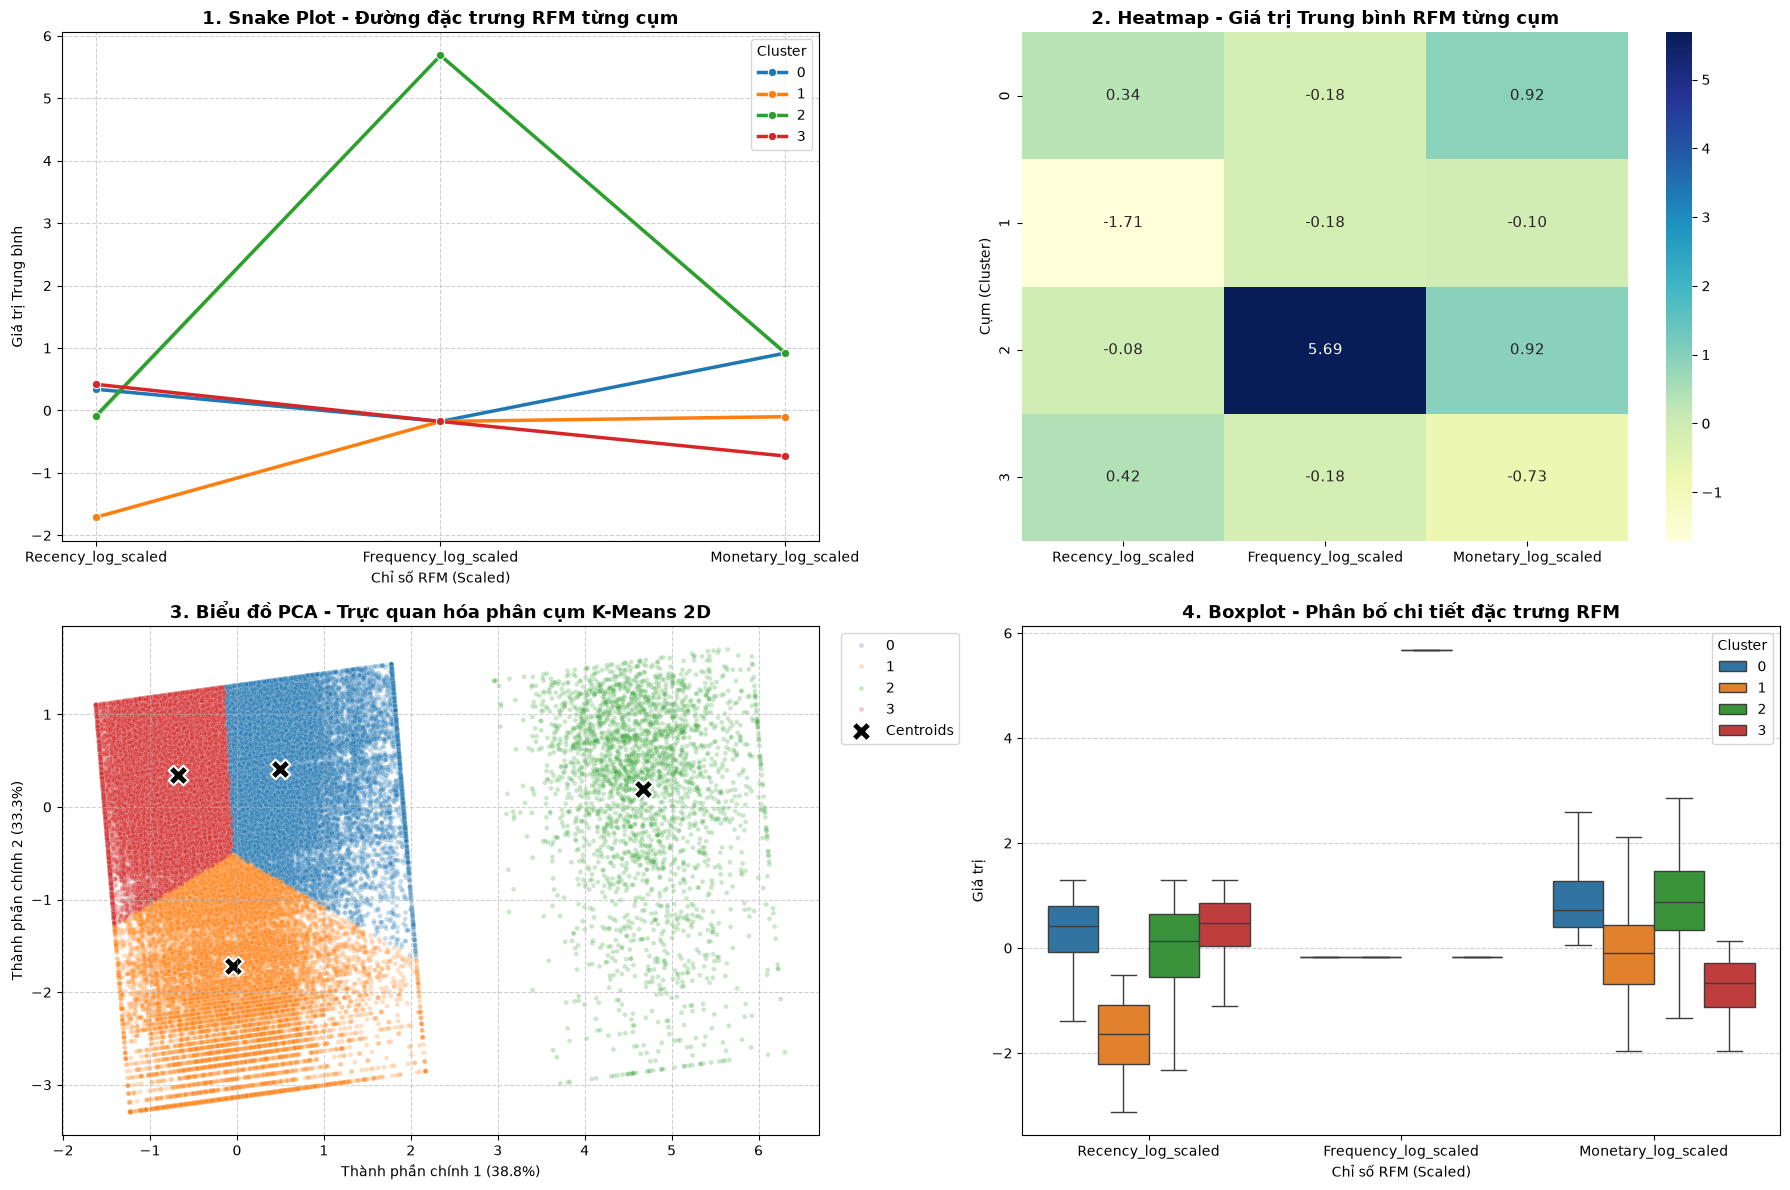

=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM ===
         Recency_log_scaled  Frequency_log_scaled  Monetary_log_scaled  \
Cluster                                                                  
0                  0.339784             -0.175873             0.917738   
1                 -1.709529             -0.175873            -0.099369   
2                 -0.084969              5.685937             0.924636   
3                  0.418590             -0.175873            -0.729538   

         So_luong  Ty_le_%  
Cluster                     
0           32218    34.51  
1           16507    17.68  
2            2801     3.00  
3           41831    44.81  


In [6]:
import sys
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

# Add thư mục src vào sys.path để import hàm nếu notebook nằm trong thư mục notebooks/
sys.path.append(os.path.abspath("../src"))

# Import hàm train K-Means (thay 'train_kmeans' bằng tên file python chứa hàm của bạn)
from clustering import train_and_save_kmeans

# 1. Gọi hàm để thực hiện train K-Means, gán nhãn và xuất file kết quả
model, df = train_and_save_kmeans(
    data_path="../data/processed/rfm_features_scaled.csv",
    model_save_path="../models/kmeans_rfm_model.pkl",
    output_csv_path="../data/processed/rfm_kmeans_clustered.csv",
    n_clusters=4,
    random_state=42,
)

# Khai báo các cột thuộc tính RFM đã scale
feature_cols = [
    "Recency_log_scaled",
    "Frequency_log_scaled",
    "Monetary_log_scaled",
]
X = df[feature_cols].values

# 2. Giảm chiều dữ liệu bằng PCA xuống 2D để trực quan hóa
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X)
df["PCA1"] = pca_features[:, 0]
df["PCA2"] = pca_features[:, 1]

# Tính giá trị trung bình RFM theo từng cụm
cluster_summary = df.groupby("Cluster")[feature_cols].mean()

# 3. Vẽ bộ biểu đồ trực quan hóa đánh giá đặc điểm các cụm
fig = plt.figure(figsize=(18, 12))

# --- Biểu đồ 1: Snake Plot (Đường đặc trưng RFM) ---
plt.subplot(2, 2, 1)
df_melt = pd.melt(
    df,
    id_vars=["Cluster"],
    value_vars=feature_cols,
    var_name="Metric",
    value_name="Value",
)
sns.lineplot(
    data=df_melt,
    x="Metric",
    y="Value",
    hue="Cluster",
    palette="tab10",
    marker="o",
    linewidth=2.5,
)
plt.title(
    "1. Snake Plot - Đường đặc trưng RFM từng cụm",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlabel("Chỉ số RFM (Scaled)")
plt.ylabel("Giá trị Trung bình")

# --- Biểu đồ 2: Heatmap Giá trị Trung bình ---
plt.subplot(2, 2, 2)
sns.heatmap(
    cluster_summary,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    cbar=True,
    annot_kws={"size": 11},
)
plt.title(
    "2. Heatmap - Giá trị Trung bình RFM từng cụm",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Cụm (Cluster)")

# --- Biểu đồ 3: Biểu đồ PCA Phân cụm 2D (Đã tối ưu điểm thưa & Vẽ tâm cụm) ---
plt.subplot(2, 2, 3)

# 1. Chiếu điểm dữ liệu sang không gian PCA 2D
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X)
df["PCA1"] = pca_features[:, 0]
df["PCA2"] = pca_features[:, 1]

# 2. Chiếu tâm cụm (Centroids) của K-Means sang không gian PCA 2D
centroids_pca = pca.transform(model.cluster_centers_)

# 3. Vẽ các điểm dữ liệu (chỉnh alpha nhẹ và kích thước nhỏ hơn để thấy rõ độ thưa)
sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="tab10",
    alpha=0.25,  # Giảm độ mờ để hiện rõ mật độ/độ thưa
    s=12,  # Giảm kích thước điểm tránh đè lấp
    legend="full",
)

# 4. Vẽ đánh dấu các tâm cụm (Centroids)
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    s=200,  # Kích thước tâm cụm lớn
    c="black",  # Màu tâm
    marker="X",  # Dấu X làm nổi bật
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
)

plt.title(
    "3. Biểu đồ PCA - Trực quan hóa phân cụm K-Means 2D",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(
    f"Thành phần chính 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"Thành phần chính 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")  # Đưa chú thích ra ngoài

# --- Biểu đồ 4: Boxplot độ phân tán chi tiết ---
plt.subplot(2, 2, 4)
sns.boxplot(
    data=df_melt,
    x="Metric",
    y="Value",
    hue="Cluster",
    palette="tab10",
    showfliers=False,
)
plt.title(
    "4. Boxplot - Phân bố chi tiết đặc trưng RFM",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Chỉ số RFM (Scaled)")
plt.ylabel("Giá trị")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Xuất bảng tổng hợp kết quả ra màn hình
print("=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM ===")
summary_table = cluster_summary.copy()
summary_table["So_luong"] = df["Cluster"].value_counts()
summary_table["Ty_le_%"] = (
    df["Cluster"].value_counts(normalize=True) * 100
).round(2)
print(summary_table)

**K-Medoids**

Kích thước tập dữ liệu đầu vào: 93357 dòng, 3 cột
Đang train K-Medoids (K=4) trên toàn bộ dữ liệu...
   Hoàn thành vòng lặp 1 - Thời gian đã chạy: 9.18s
   Hoàn thành vòng lặp 2 - Thời gian đã chạy: 27.20s
   Hoàn thành vòng lặp 3 - Thời gian đã chạy: 52.53s
   Hoàn thành vòng lặp 4 - Thời gian đã chạy: 74.08s
   Hoàn thành vòng lặp 5 - Thời gian đã chạy: 99.90s
   Hoàn thành vòng lặp 6 - Thời gian đã chạy: 121.56s
   Hoàn thành vòng lặp 7 - Thời gian đã chạy: 145.77s
   Hoàn thành vòng lặp 8 - Thời gian đã chạy: 170.48s
   Hoàn thành vòng lặp 9 - Thời gian đã chạy: 194.48s
   Hoàn thành vòng lặp 10 - Thời gian đã chạy: 218.88s
   Hoàn thành vòng lặp 11 - Thời gian đã chạy: 243.50s
   Hoàn thành vòng lặp 12 - Thời gian đã chạy: 267.92s
   Hoàn thành vòng lặp 13 - Thời gian đã chạy: 284.82s
   Hoàn thành vòng lặp 14 - Thời gian đã chạy: 300.58s
   Hoàn thành vòng lặp 15 - Thời gian đã chạy: 311.85s
   Hoàn thành vòng lặp 16 - Thời gian đã chạy: 335.81s
   Hoàn thành vòng lặp 17 - Thời g

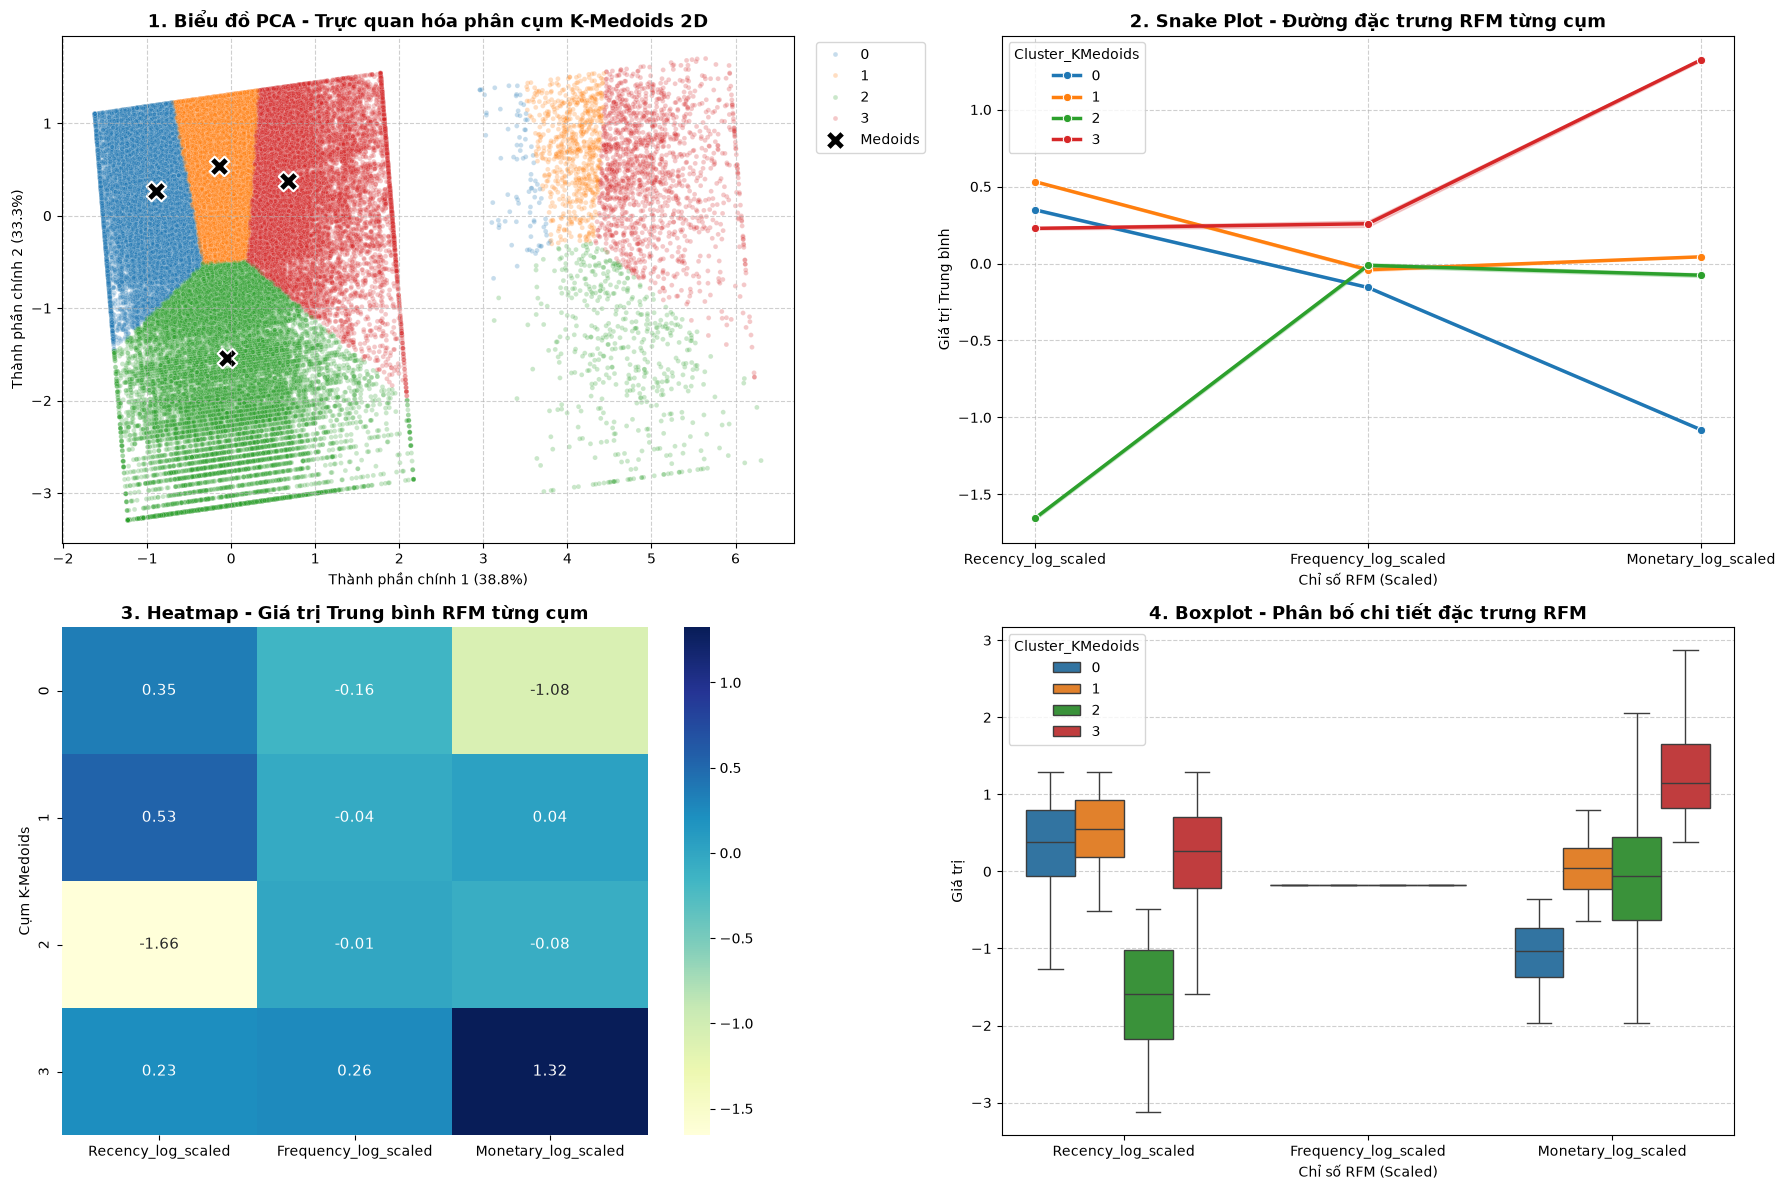

=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM K-MEDOIDS ===
                  Recency_log_scaled  Frequency_log_scaled  \
Cluster_KMedoids                                             
0                           0.349157             -0.155651   
1                           0.532159             -0.040041   
2                          -1.655604             -0.011934   
3                           0.228378              0.258399   

                  Monetary_log_scaled  So_luong  Ty_le_%  
Cluster_KMedoids                                          
0                           -1.080155     25220    27.01  
1                            0.043639     29777    31.90  
2                           -0.075942     17735    19.00  
3                            1.323098     20625    22.09  


In [7]:
import os
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

# Add thư mục src vào sys.path để import hàm từ thư mục src
sys.path.append(os.path.abspath("../src"))

# Import hàm train K-Medoids (thay 'train_kmedoids' bằng tên file python chứa hàm của bạn)
from clustering import train_and_save_kmedoids

# 1. Gọi hàm để thực hiện train K-Medoids, gán nhãn và xuất file kết quả
model_dict, df = train_and_save_kmedoids(
    data_path="../data/processed/rfm_features_scaled.csv",
    model_save_path="../models/kmedoids_rfm_model.pkl",
    k=4,
    max_iter=20,
    random_state=42,
    batch_size=5000,
)

# Khai báo thuộc tính RFM
feature_cols = [
    "Recency_log_scaled",
    "Frequency_log_scaled",
    "Monetary_log_scaled",
]
X = df[feature_cols].values

# 2. Chiếu dữ liệu và tâm Medoids sang không gian PCA 2D
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X)
df["PCA1"] = pca_features[:, 0]
df["PCA2"] = pca_features[:, 1]

# Lấy tọa độ tâm Medoids và chiếu sang PCA 2D
medoids_scaled = model_dict["medoids"]
medoids_pca = pca.transform(medoids_scaled)

# Tính giá trị trung bình RFM theo từng cụm K-Medoids
cluster_summary = df.groupby("Cluster_KMedoids")[feature_cols].mean()

# 3. Vẽ bộ 4 biểu đồ trực quan hóa đánh giá K-Medoids
fig = plt.figure(figsize=(18, 12))

# --- Biểu đồ 1: Biểu đồ PCA Phân cụm 2D (Có dấu Medoids) ---
plt.subplot(2, 2, 1)
sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="Cluster_KMedoids",
    palette="tab10",
    alpha=0.25,  # Giảm độ mờ để hiện rõ độ thưa của các cụm
    s=12,  # Kích thước điểm nhỏ tránh đè lấp
    legend="full",
)

# Vẽ đánh dấu các tâm Medoids
plt.scatter(
    medoids_pca[:, 0],
    medoids_pca[:, 1],
    s=200,  # Kích thước tâm nổi bật
    c="black",
    marker="X",  # Dấu X thể hiện tâm Medoid
    edgecolor="white",
    linewidth=1.5,
    label="Medoids",
)

plt.title(
    "1. Biểu đồ PCA - Trực quan hóa phân cụm K-Medoids 2D",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(
    f"Thành phần chính 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"Thành phần chính 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

# --- Biểu đồ 2: Snake Plot (Đường đặc trưng RFM) ---
plt.subplot(2, 2, 2)
df_melt = pd.melt(
    df,
    id_vars=["Cluster_KMedoids"],
    value_vars=feature_cols,
    var_name="Metric",
    value_name="Value",
)
sns.lineplot(
    data=df_melt,
    x="Metric",
    y="Value",
    hue="Cluster_KMedoids",
    palette="tab10",
    marker="o",
    linewidth=2.5,
)
plt.title(
    "2. Snake Plot - Đường đặc trưng RFM từng cụm",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlabel("Chỉ số RFM (Scaled)")
plt.ylabel("Giá trị Trung bình")

# --- Biểu đồ 3: Heatmap Giá trị Trung bình ---
plt.subplot(2, 2, 3)
sns.heatmap(
    cluster_summary,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    cbar=True,
    annot_kws={"size": 11},
)
plt.title(
    "3. Heatmap - Giá trị Trung bình RFM từng cụm",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Cụm K-Medoids")

# --- Biểu đồ 4: Boxplot độ phân tán chi tiết ---
plt.subplot(2, 2, 4)
sns.boxplot(
    data=df_melt,
    x="Metric",
    y="Value",
    hue="Cluster_KMedoids",
    palette="tab10",
    showfliers=False,
)
plt.title(
    "4. Boxplot - Phân bố chi tiết đặc trưng RFM",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Chỉ số RFM (Scaled)")
plt.ylabel("Giá trị")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Xuất bảng tổng hợp kết quả ra màn hình
print("=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM K-MEDOIDS ===")
summary_table = cluster_summary.copy()
summary_table["So_luong"] = df["Cluster_KMedoids"].value_counts()
summary_table["Ty_le_%"] = (
    df["Cluster_KMedoids"].value_counts(normalize=True) * 100
).round(2)
print(summary_table)

**C-Means**

Kích thước tập dữ liệu đầu vào: 93357 dòng, 3 cột
Đang train mô hình Fuzzy C-Means (C=4, m=2.0)...
💾 Đã lưu mô hình FCM tại: ../models/fcm_rfm_model.pkl
📊 Đã lưu DataFrame kết quả phân cụm mờ tại: ../data/processed/rfm_fcm_clustered.csv


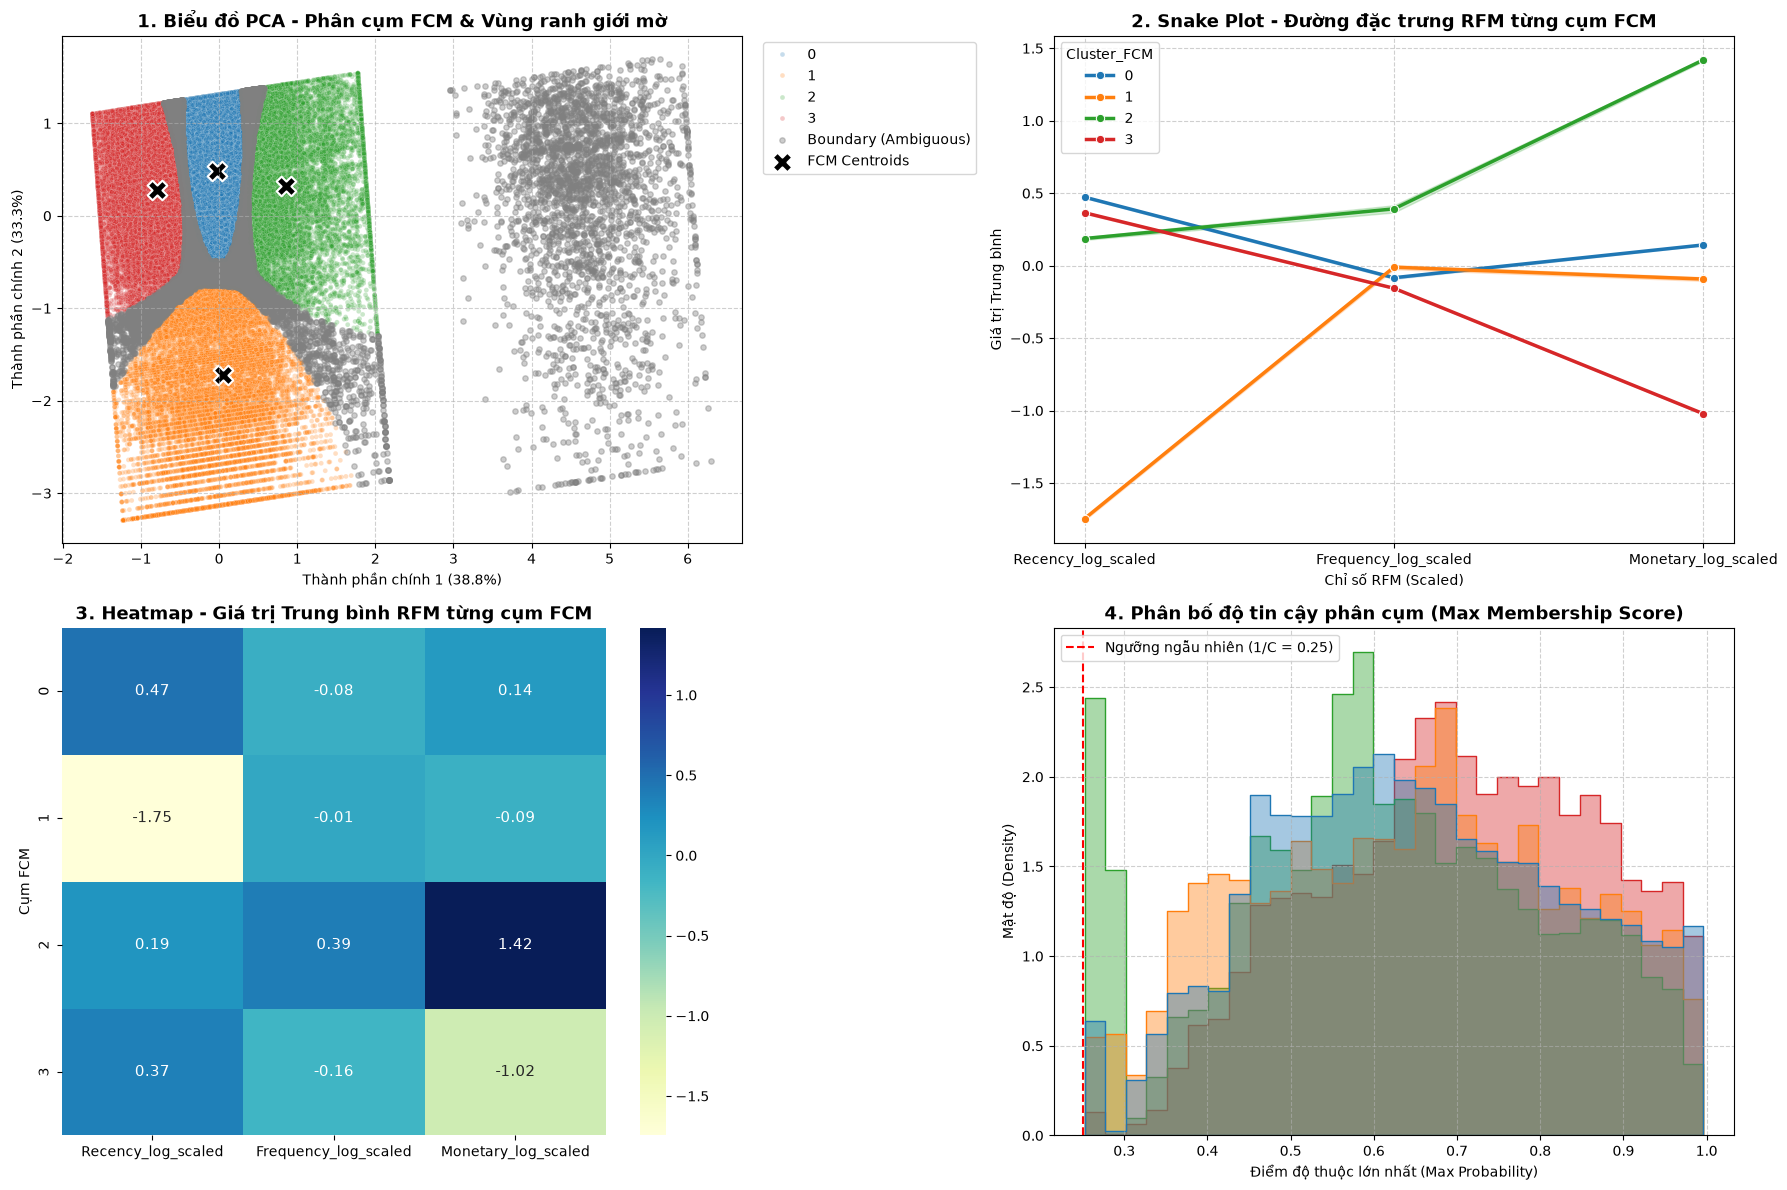

=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM FUZZY C-MEANS ===
             Recency_log_scaled  Frequency_log_scaled  Monetary_log_scaled  \
Cluster_FCM                                                                  
0                      0.472771             -0.083281             0.142962   
1                     -1.746215             -0.010710            -0.092431   
2                      0.187107              0.391888             1.419953   
3                      0.365281             -0.156083            -1.021952   

             So_luong  Ty_le_%  Max_Prob_Mean  So_luong_Ranh_gioi  
Cluster_FCM                                                        
0               30831    33.02          0.652                5881  
1               16184    17.34          0.643                2509  
2               18202    19.50          0.614                4392  
3               28140    30.14          0.701                3300  


In [1]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

# Add thư mục src vào sys.path để import hàm từ thư mục src
sys.path.append(os.path.abspath("../src"))

# Import hàm train Fuzzy C-Means (thay 'train_fcm' bằng tên file python chứa hàm của bạn)
from clustering import train_and_save_fcm

# 1. Gọi hàm thực hiện train FCM, gán nhãn, độ thuộc và xuất file kết quả
model_dict, df = train_and_save_fcm(
    data_path="../data/processed/rfm_features_scaled.csv",
    model_save_path="../models/fcm_rfm_model.pkl",
    output_csv_path="../data/processed/rfm_fcm_clustered.csv",
    c=4,
    m=2.0,
    max_iter=100,
    error=1e-5,
    random_state=42,
)

# Khai báo các thuộc tính RFM
feature_cols = [
    "Recency_log_scaled",
    "Frequency_log_scaled",
    "Monetary_log_scaled",
]
X = df[feature_cols].values

# 2. Tính toán bổ sung cho phân tích mờ (Ranh giới & Độ tin cậy)
U = model_dict["u_matrix"]
centroids = model_dict["centroids"]

# Tính chênh lệch xác suất giữa 2 cụm cao nhất để tìm khách hàng ở vùng ranh giới
U_sorted = np.sort(U, axis=0)[::-1]
df["Top1_Prob"] = U_sorted[0]
df["Top2_Prob"] = U_sorted[1]
df["Diff_Prob"] = df["Top1_Prob"] - df["Top2_Prob"]
df["Is_Boundary"] = df["Diff_Prob"] < 0.15  # Khách hàng phân vân giữa 2 cụm

# Chiếu dữ liệu và tâm cụm FCM sang PCA 2D
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X)
df["PCA1"] = pca_features[:, 0]
df["PCA2"] = pca_features[:, 1]
centroids_pca = pca.transform(centroids)

# Tính giá trị trung bình RFM theo từng cụm FCM
cluster_summary = df.groupby("Cluster_FCM")[feature_cols].mean()

# 3. Vẽ bộ 4 biểu đồ trực quan hóa đặc trưng Fuzzy C-Means
fig = plt.figure(figsize=(18, 12))

# --- Biểu đồ 1: PCA Trực quan hóa Phân cụm mờ & Ranh giới ---
plt.subplot(2, 2, 1)
# Vẽ các điểm dữ liệu thường
sns.scatterplot(
    data=df[~df["Is_Boundary"]],
    x="PCA1",
    y="PCA2",
    hue="Cluster_FCM",
    palette="tab10",
    alpha=0.25,
    s=12,
    legend="full",
)

# Highlight các điểm thuộc vùng ranh giới (Boundary) bằng màu xám nhẹ
plt.scatter(
    df[df["Is_Boundary"]]["PCA1"],
    df[df["Is_Boundary"]]["PCA2"],
    c="gray",
    s=15,
    alpha=0.4,
    label="Boundary (Ambiguous)",
)

# Vẽ đánh dấu các tâm cụm FCM
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    s=200,
    c="black",
    marker="X",
    edgecolor="white",
    linewidth=1.5,
    label="FCM Centroids",
)

plt.title(
    "1. Biểu đồ PCA - Phân cụm FCM & Vùng ranh giới mờ",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(
    f"Thành phần chính 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"Thành phần chính 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

# --- Biểu đồ 2: Snake Plot (Đường đặc trưng RFM) ---
plt.subplot(2, 2, 2)
df_melt = pd.melt(
    df,
    id_vars=["Cluster_FCM"],
    value_vars=feature_cols,
    var_name="Metric",
    value_name="Value",
)
sns.lineplot(
    data=df_melt,
    x="Metric",
    y="Value",
    hue="Cluster_FCM",
    palette="tab10",
    marker="o",
    linewidth=2.5,
)
plt.title(
    "2. Snake Plot - Đường đặc trưng RFM từng cụm FCM",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlabel("Chỉ số RFM (Scaled)")
plt.ylabel("Giá trị Trung bình")

# --- Biểu đồ 3: Heatmap Giá trị Trung bình ---
plt.subplot(2, 2, 3)
sns.heatmap(
    cluster_summary,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    cbar=True,
    annot_kws={"size": 11},
)
plt.title(
    "3. Heatmap - Giá trị Trung bình RFM từng cụm FCM",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Cụm FCM")

# --- Biểu đồ 4: Phân bố độ tin cậy độ thuộc (Membership Certainty) ---
plt.subplot(2, 2, 4)
sns.histplot(
    data=df,
    x="Max_Membership_Score",
    hue="Cluster_FCM",
    palette="tab10",
    element="step",
    stat="density",
    common_norm=False,
    bins=30,
    alpha=0.4,
)
plt.axvline(
    x=0.25,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Ngưỡng ngẫu nhiên (1/C = 0.25)",
)
plt.title(
    "4. Phân bố độ tin cậy phân cụm (Max Membership Score)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Điểm độ thuộc lớn nhất (Max Probability)")
plt.ylabel("Mật độ (Density)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

# 4. Xuất bảng tổng hợp kết quả ra màn hình
print("=== BẢNG TÓM TẮT ĐẶC TRƯNG CÁC CỤM FUZZY C-MEANS ===")
summary_table = cluster_summary.copy()
summary_table["So_luong"] = df["Cluster_FCM"].value_counts()
summary_table["Ty_le_%"] = (
    df["Cluster_FCM"].value_counts(normalize=True) * 100
).round(2)
summary_table["Max_Prob_Mean"] = (
    df.groupby("Cluster_FCM")["Max_Membership_Score"].mean().round(3)
)
summary_table["So_luong_Ranh_gioi"] = (
    df[df["Is_Boundary"]]["Cluster_FCM"].value_counts().fillna(0).astype(int)
)
print(summary_table)